In [1]:
import torch 
import torch.nn.functional as F 
import matplotlib.pyplot as plt 

In [2]:
words = open('names (1).txt','r').read().splitlines() 

In [3]:
chars= sorted(list(set(''.join(words))))
mapping  = {c : i+1  for i,c in enumerate(chars)}
mapping['.'] = 0
reverse_mapping = {i:c for c,i in mapping.items()}
vocab_size = len(reverse_mapping)
print(reverse_mapping)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [4]:
import random
block_size = 3
def Build_dataset(words):
    
    X , y = [] , []
    for w in words:
        #print(w)
        context = [0]*block_size
        for ch in w + '.':
            ix = mapping[ch]
            X.append(context)
            y.append(ix)
            #print(''.join(reverse_mapping[i] for i in context) ,'---->' , reverse_mapping[ix])
            context = context[1:] + [ix]
        
    X=torch.tensor(X)
    y=torch.tensor(y)
    return X ,y

random.seed(42)
random.shuffle(words)
n1 =int(0.8*len(words))
n2 =int(0.9*len(words))

Xtr , ytr = Build_dataset(words[:n1])
Xdv , ydv = Build_dataset(words[n1:n2])
Xts , yts = Build_dataset(words[n2:])

In [5]:
for x,y in zip(Xtr[:20] , ytr[:20]):
    print(''.join(reverse_mapping[ix.item()] for ix in x) , '---->', reverse_mapping[y.item()])

... ----> y
..y ----> u
.yu ----> h
yuh ----> e
uhe ----> n
hen ----> g
eng ----> .
... ----> d
..d ----> i
.di ----> o
dio ----> n
ion ----> d
ond ----> r
ndr ----> e
dre ----> .
... ----> x
..x ----> a
.xa ----> v
xav ----> i
avi ----> e


In [9]:
class Linear:
    def __init__(self , fanin , fanout ,bias = True):
        self.weight = torch.randn((fanin , fanout)  ) / fanout **0.5
        self.bias = torch.zeros(fanout) if bias else None 

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out
    def parameters(self):
        params = [self.weight]
        if self.bias is not None:
            params.append(self.bias)
        return params 


class Batchnorm1d:
    def __init__(self , dim , epslon =1e-5 , momentum=0.1):
        self.epslon = epslon 
        self.momentum = momentum
        self.training = True
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        if self.training:
            xmean = x.mean(0 , keepdim=True)
            xvar = x.var(0 , keepdim=True)
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x -xmean) / torch.sqrt(xvar + self.epslon)
        self.out = self.gamma * xhat + self.beta
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum )*self.running_mean + self.momentum  * xmean
                self.running_var = (1 - self.momentum )*self.running_var + self.momentum  * xvar
        return self.out
    def parameters(self):
        return [self.beta , self.gamma]

class Tanh:
    def __call__(self,x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []

    
class Embedding:
    def __init__(self,num_embedding, num_dim):
        self.weight = torch.randn((num_embedding, num_dim))
    def __call__(self ,IX):
        self.out = self.weight[IX]
        return self.out
    def parameters(self):
        return [self.weight]

    
class Flatten:
    def __call__(self ,x):
        self.out = x.view(x.shape[0], -1)
        return self.out
    def parameters(self):
        return []

class Sequential:
    def __init__(self , layers):
        self.layers= layers
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out
    def parameters(self):
        return [ p for layer in self.layers for p in layer.parameters()]
        

In [14]:
torch.manual_seed(42)

In [ ]:
n_embd = 10
n_hidden = 200
model =Sequential( [
    Embedding(vocab_size , n_embd),
    Flatten(),
    Linear(n_embd*block_size , n_hidden ,bias=False) ,Batchnorm1d(n_hidden), Tanh() , 
    Linear(n_hidden,vocab_size) ,
])

with torch.no_grad():
    model.layers[-1].weight *=0.1

parameters =model.parameters()
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad =True


12097


In [21]:
max_steps = 200000
lossi = []
batch_size = 32

for i in range(max_steps):
    #minibatch
    ix = torch.randint(0 , Xtr.shape[0] , (batch_size,  ))
    xb = Xtr[ix]
    yb = ytr[ix]

    #forward pass 
    logits = model(xb)
    loss = F.cross_entropy(logits , yb)
    
    #backward pass
    for p in parameters:
        p.grad= None
    loss.backward()

    #update 
    lr = 0.1 if i < 10000 else 0.01 
    for p in parameters:
        p.data += - lr* p.grad
    # lri.append(lre[i])
    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    

      0/200000: 3.2147
  10000/200000: 2.2033
  20000/200000: 1.9636
  30000/200000: 2.1889
  40000/200000: 2.4844
  50000/200000: 2.4612
  60000/200000: 2.0230
  70000/200000: 2.1947
  80000/200000: 2.1013
  90000/200000: 2.3341
 100000/200000: 2.1620
 110000/200000: 2.3052
 120000/200000: 2.0614
 130000/200000: 2.8357
 140000/200000: 2.1228
 150000/200000: 1.8375
 160000/200000: 2.1293
 170000/200000: 1.9878
 180000/200000: 2.1748
 190000/200000: 2.0006


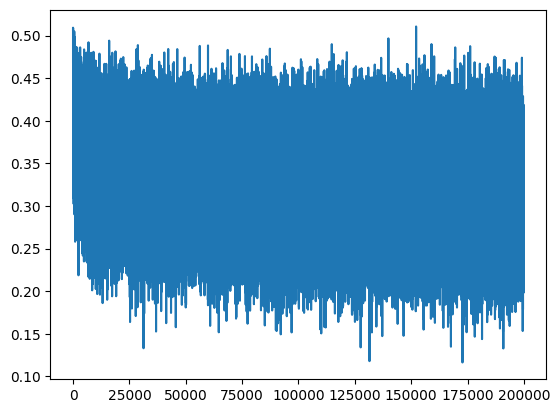

In [22]:
plt.plot(lossi)

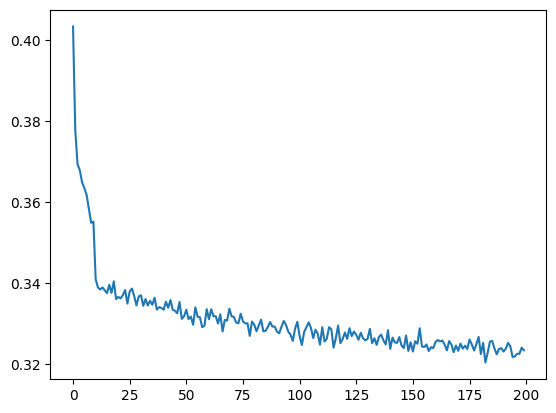

In [23]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))

In [24]:
for layer in model.layers:
    layer.training = False

In [25]:
@torch.no_grad()
def split_loss(split):
    x,y = {
        'train': (Xtr , ytr),
        'val': (Xdv , ydv),
        'test': (Xts , yts)
    }[split]
    logits = model(x)
    loss =F.cross_entropy(logits , y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0896713733673096
val 2.1260828971862793


In [26]:


for i in range(20):
    out = []
    context = [0]*block_size  
    while True:
        logits = model(torch.tensor([context]))
        prob = F.softmax(logits, dim=1)
        ix = torch.multinomial(prob , num_samples = 1 ).item()
        context = context[1:]+ [ix]
        out.append(ix)
        if ix== 0 :
            break 

    print(''.join(reverse_mapping[i] for i in out))

jermanika.
alesjehani.
kaev.
brotiel.
nishina.
jaan.
kaimedan.
kathmya.
garie.
dayvion.
bariandra.
win.
ady.
taswinleigh.
jena.
carrius.
kea.
guriela.
turah.
skyrolyn.


In [27]:
import random
block_size = 8
def Build_dataset(words):
    
    X , y = [] , []
    for w in words:
        #print(w)
        context = [0]*block_size
        for ch in w + '.':
            ix = mapping[ch]
            X.append(context)
            y.append(ix)
            #print(''.join(reverse_mapping[i] for i in context) ,'---->' , reverse_mapping[ix])
            context = context[1:] + [ix]
        
    X=torch.tensor(X)
    y=torch.tensor(y)
    return X ,y

random.seed(42)
random.shuffle(words)
n1 =int(0.8*len(words))
n2 =int(0.9*len(words))

Xtr , ytr = Build_dataset(words[:n1])
Xdv , ydv = Build_dataset(words[n1:n2])
Xts , yts = Build_dataset(words[n2:])

In [28]:
for x,y in zip(Xtr[:20] , ytr[:20]):
    print(''.join(reverse_mapping[ix.item()] for ix in x) , '---->', reverse_mapping[y.item()])

........ ----> e
.......e ----> b
......eb ----> r
.....ebr ----> i
....ebri ----> m
...ebrim ----> a
..ebrima ----> .
........ ----> h
.......h ----> i
......hi ----> l
.....hil ----> t
....hilt ----> o
...hilto ----> n
..hilton ----> .
........ ----> j
.......j ----> h
......jh ----> e
.....jhe ----> n
....jhen ----> e
...jhene ----> .


In [47]:
class Linear:
    def __init__(self , fanin , fanout ,bias = True):
        self.weight = torch.randn((fanin , fanout)  ) / fanout **0.5
        self.bias = torch.zeros(fanout) if bias else None 

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out
    def parameters(self):
        params = [self.weight]
        if self.bias is not None:
            params.append(self.bias)
        return params 


class Batchnorm1d:
    def __init__(self , dim , epslon =1e-5 , momentum=0.1):
        self.epslon = epslon 
        self.momentum = momentum
        self.training = True
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        if self.training:
            if x.ndim == 2:
                dim = 0 
            elif x.ndim == 3:
                dim =(0,1)
            xmean = x.mean(dim , keepdim=True)
            xvar = x.var(dim , keepdim=True)
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x -xmean) / torch.sqrt(xvar + self.epslon)
        self.out = self.gamma * xhat + self.beta
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum )*self.running_mean + self.momentum  * xmean
                self.running_var = (1 - self.momentum )*self.running_var + self.momentum  * xvar
        return self.out
    def parameters(self):
        return [self.beta , self.gamma]

class Tanh:
    def __call__(self,x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []

    
class Embedding:
    def __init__(self,num_embedding, num_dim):
        self.weight = torch.randn((num_embedding, num_dim))
    def __call__(self ,IX):
        self.out = self.weight[IX]
        return self.out
    def parameters(self):
        return [self.weight]

    
class FlattenConsecutive:
    def __init__(self , n):
        self.n = n
    def __call__(self ,x):
        B , T ,C = x.shape
        x = x.view(B, T//self.n ,C*self.n )
        if x.shape[1] ==1:
            x=x.squeeze(1)
        self.out = x 
        return self.out
    def parameters(self):
        return []

class Sequential:
    def __init__(self , layers):
        self.layers= layers
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out
    def parameters(self):
        return [ p for layer in self.layers for p in layer.parameters()]
        

In [48]:
n_embd = 24
n_hidden = 128
model =Sequential( [
    Embedding(vocab_size , n_embd),
    FlattenConsecutive(2), Linear(n_embd*2 , n_hidden ,bias=False) ,Batchnorm1d(n_hidden), Tanh() , 
    FlattenConsecutive(2), Linear(n_hidden*2 , n_hidden ,bias=False) ,Batchnorm1d(n_hidden), Tanh() ,
    FlattenConsecutive(2), Linear(n_hidden*2 , n_hidden ,bias=False) ,Batchnorm1d(n_hidden), Tanh() ,
    Linear(n_hidden,vocab_size) ,
])

with torch.no_grad():
    model.layers[-1].weight *=0.1

parameters =model.parameters()
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad =True

76579


In [49]:
max_steps = 200000
lossi = []
batch_size = 32

for i in range(max_steps):
    #minibatch
    ix = torch.randint(0 , Xtr.shape[0] , (batch_size,  ))
    xb = Xtr[ix]
    yb = ytr[ix]

    #forward pass 
    logits = model(xb)
    loss = F.cross_entropy(logits , yb)
    
    #backward pass
    for p in parameters:
        p.grad= None
    loss.backward()

    #update 
    lr = 0.1 if i < 10000 else 0.01 
    for p in parameters:
        p.data += - lr* p.grad
    # lri.append(lre[i])
    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    

      0/200000: 3.2896
  10000/200000: 2.0743
  20000/200000: 2.0277
  30000/200000: 1.8518
  40000/200000: 1.9814
  50000/200000: 2.1073
  60000/200000: 1.6692
  70000/200000: 2.1928
  80000/200000: 1.9658
  90000/200000: 1.9395
 100000/200000: 1.8527
 110000/200000: 1.9323
 120000/200000: 1.8502
 130000/200000: 1.8679
 140000/200000: 2.0893
 150000/200000: 1.6651
 160000/200000: 2.0263
 170000/200000: 1.6915
 180000/200000: 1.7557
 190000/200000: 1.5631


In [50]:
for layer in model.layers:
    layer.training = False

In [51]:
@torch.no_grad()
def split_loss(split):
    x,y = {
        'train': (Xtr , ytr),
        'val': (Xdv , ydv),
        'test': (Xts , yts)
    }[split]
    logits = model(x)
    loss =F.cross_entropy(logits , y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 1.8563542366027832
val 2.006948947906494


In [52]:


for i in range(20):
    out = []
    context = [0]*block_size  
    while True:
        logits = model(torch.tensor([context]))
        prob = F.softmax(logits, dim=1)
        ix = torch.multinomial(prob , num_samples = 1 ).item()
        context = context[1:]+ [ix]
        out.append(ix)
        if ix== 0 :
            break 

    print(''.join(reverse_mapping[i] for i in out))

rinlee.
margelio.
mariama.
brentzy.
ahsab.
amariya.
milena.
yassain.
sophie.
tairee.
ousna.
junuel.
yeila.
rickinsre.
samaya.
lakenz.
edelie.
tomber.
winnz.
jessleen.
